619 days | pre 84.9 (364d) | post 6.1 (253d) | -92.8% | record 133 (9 Jun 2025) | post-war high 51 (24 Jun 2026) | 14 zero days
Saved index.html


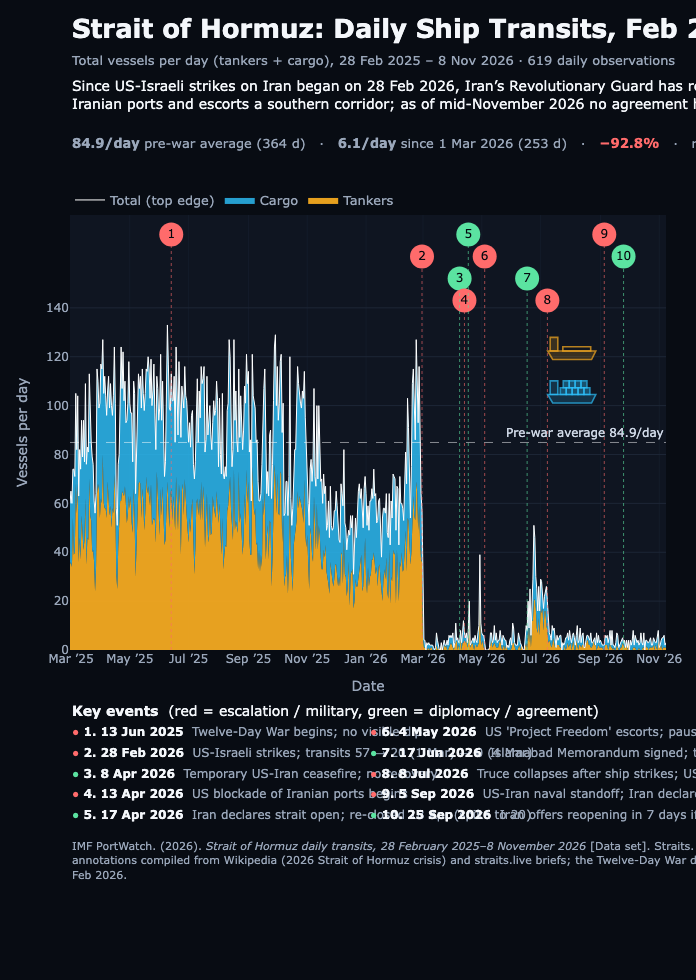

In [1]:
#!/usr/bin/env python3
"""
Strait of Hormuz: Daily Ship Transits, Feb 2025 - Nov 2026  (interactive Plotly version)

Hover for daily counts; zoom/pan; click legend items to toggle tankers/cargo; hover event markers.
Writes a standalone HTML page you can host with GitHub Pages.
"""
import sys
import textwrap
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go

# Relative paths (looks in the same folder as the script/notebook)
OFFLINE = False
CSV = Path("straits-transits.csv")
OUT = Path("index.html")   # index.html => GitHub Pages home

BG, PANEL, INK, MUTE, GRID = "#080c13", "#0f1521", "#f4f7fb", "#9aa7ba", "#1d2636"
TANK, CARGO, ESC, DIP = "#ffb020", "#2ec4ff", "#ff6b6b", "#5be3a1"

# ---- load + audit -----------------------------------------------------------
if not CSV.exists():
    sys.exit(f"CSV not found: {CSV}. Make sure it is in the same folder as this script.")
df = pd.read_csv(CSV, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
assert not df.date.duplicated().any(), "duplicate dates"
assert df.date.diff().dropna().eq(pd.Timedelta(days=1)).all(), "gaps in daily series"
assert not df.isna().any().any(), "null values"
assert (df.n_total == df.n_tanker + df.n_cargo).all(), "total != tanker + cargo"

pre = df[(df.date >= "2025-03-01") & (df.date <= "2026-02-27")].n_total
post = df[df.date >= "2026-03-01"].n_total
pre_avg, post_avg = pre.mean(), post.mean()
drop = (1 - post_avg / pre_avg) * 100
peak = df.loc[df.n_total.idxmax()]
ppk = df.loc[df[df.date >= "2026-03-01"].n_total.idxmax()]
zeros = int((df.n_total == 0).sum())
fmt = lambda d: f"{d.day} {d:%b %Y}"
print(f"{len(df)} days | pre {pre_avg:.1f} ({len(pre)}d) | post {post_avg:.1f} ({len(post)}d) | -{drop:.1f}% | "
      f"record {peak.n_total} ({fmt(peak.date)}) | post-war high {ppk.n_total} ({fmt(ppk.date)}) | {zeros} zero days")

EVENTS = [
    ("2025-06-13", "Twelve-Day War begins; no visible dip", "e"),
    ("2026-02-28", "US-Israeli strikes; transits 57 \u2192 20 (1 Mar) \u2192 0 (4 Mar)", "e"),
    ("2026-04-08", "Temporary US-Iran ceasefire; no recovery", "d"),
    ("2026-04-13", "US blockade of Iranian ports begins", "e"),
    ("2026-04-17", "Iran declares strait open; re-closed 18 Apr (spike to 20)", "d"),
    ("2026-05-04", "US 'Project Freedom' escorts; paused 6 May (0 on 5-8 May)", "e"),
    ("2026-06-17", "Islamabad Memorandum signed; transits peak at 51 on 24 Jun", "d"),
    ("2026-07-08", "Truce collapses after ship strikes; US blockade back 14 Jul", "e"),
    ("2026-09-05", "US-Iran naval standoff; Iran declares 'prohibited zone'", "e"),
    ("2026-09-25", "Iran offers reopening in 7 days if US accepts plan; no change", "d"),
]
BLURB = ("Since US-Israeli strikes on Iran began on 28 Feb 2026, Iran\u2019s Revolutionary Guard has restricted the strait "
         "to approved ships while the US blockades Iranian ports and escorts a southern corridor; as of mid-November "
         "2026 no agreement has reopened it.")
CITE = ("IMF PortWatch. (2026). <i>Strait of Hormuz daily transits, 28 February 2025\u20138 November 2026</i> [Data set]. "
        "Straits. https://straits.live/data \u00a9 IMF PortWatch. Event annotations compiled from Wikipedia "
        "(2026 Strait of Hormuz crisis) and straits.live briefs; the Twelve-Day War date is added for context. "
        "Averages exclude 28 Feb 2025 and 28 Feb 2026.")

# ---- layout constants (used to keep ship drawings in proportion) -----------
HEIGHT, M = 980, dict(l=70, r=30, t=215, b=330)
PLOT_H = HEIGHT - M["t"] - M["b"]
PLOT_W = 1200                       # approximate; the page is responsive
ASPECT = PLOT_W / PLOT_H
YTOP = 178

fig = go.Figure()
fig.add_trace(go.Scatter(x=df.date, y=df.n_tanker, name="Tankers", mode="lines", stackgroup="s",
                         line=dict(width=0), fillcolor="rgba(255,176,32,0.90)", customdata=df.n_tanker,
                         hovertemplate="Tankers: %{customdata}<extra></extra>"))
fig.add_trace(go.Scatter(x=df.date, y=df.n_cargo, name="Cargo", mode="lines", stackgroup="s",
                         line=dict(width=0), fillcolor="rgba(46,196,255,0.80)", customdata=df.n_cargo,
                         hovertemplate="Cargo: %{customdata}<extra></extra>"))
fig.add_trace(go.Scatter(x=df.date, y=df.n_total, name="Total (top edge)", mode="lines",
                         line=dict(color="white", width=1), customdata=df.n_total,
                         hovertemplate="<b>Total: %{customdata}</b><extra></extra>"))

# event markers: dotted line + numbered badge (hover for the description)
rows = [0, 1, 2, 3] * 3
bx, by, bc, bt, bh = [], [], [], [], []
key_html = []
for k, (d, text, t) in enumerate(EVENTS, 1):
    ts, c = pd.Timestamp(d), (ESC if t == "e" else DIP)
    y = YTOP - 8 - rows[k - 1] * 9
    fig.add_shape(type="line", x0=ts, x1=ts, y0=0, y1=y - 3, line=dict(color=c, width=1, dash="dot"), opacity=0.6)
    bx.append(ts); by.append(y); bc.append(c); bt.append(str(k))
    bh.append(f"<b>{k}. {fmt(ts)}</b><br>{text}")
    key_html.append(f"<span style='color:{c}'>\u25cf</span> <b>{k}. {fmt(ts)}</b>  <span style='color:{MUTE}'>{text}</span>")
fig.add_trace(go.Scatter(x=bx, y=by, mode="markers+text", text=bt, textfont=dict(color="#06090f", size=12),
                         marker=dict(size=24, color=bc), hovertext=bh, hoverinfo="text", showlegend=False,
                         hoverlabel=dict(align="left")))

# pre-war average line
fig.add_shape(type="line", xref="paper", x0=0, x1=1, y0=pre_avg, y1=pre_avg,
              line=dict(color="rgba(255,255,255,0.5)", width=1, dash="dash"))
fig.add_annotation(xref="paper", x=1, y=pre_avg, yshift=10, xanchor="right", showarrow=False,
                   text=f"Pre-war average {pre_avg:.1f}/day", font=dict(color="#cfd8e6", size=12))


# helper to convert hex to rgba for Plotly compatibility
def hex_to_rgba(hex_color, alpha):
    h = hex_color.lstrip("#")
    r, g, b = tuple(int(h[i:i+2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"


# line-drawn ships (paper coordinates; 120x40 local grid scaled to w paper-units wide)
def ship(x0, y0, w, kind, color):
    h = w / 3 * ASPECT
    P = lambda u, v: f"{x0 + u / 120 * w:.5f},{y0 + v / 40 * h:.5f}"
    def poly(pts, fill):
        path = "M" + " L".join(P(*p) for p in pts) + " Z"
        fig.add_shape(type="path", xref="paper", yref="paper", path=path, fillcolor=fill,
                      line=dict(color=color, width=1.6), opacity=0.7)
    poly([(2, 14), (116, 14), (106, 4), (14, 4)], hex_to_rgba(color, 0.25))          # hull
    poly([(8, 14), (26, 14), (26, 30), (8, 30)], hex_to_rgba(color, 0.25))           # bridge
    if kind == "tanker":
        poly([(38, 14), (104, 14), (104, 19), (38, 19)], "rgba(0,0,0,0)")            # deck
    else:
        for y_, xs in ((14, range(32, 100, 14)), (22, range(39, 95, 14))):           # containers
            for x_ in xs:
                poly([(x_, y_), (x_ + 14, y_), (x_ + 14, y_ + 8), (x_, y_ + 8)], hex_to_rgba(color, 0.50))


# ship positions are in plot-area paper units; they sit in the empty post-war region
ship(0.80, 0.66, 0.085, "tanker", TANK)
ship(0.80, 0.56, 0.085, "cargo", CARGO)

# header, stats, key, citation
fig.add_annotation(xref="paper", yref="paper", x=0, y=1, yshift=205, xanchor="left", yanchor="top", showarrow=False,
                   text="<b>Strait of Hormuz: Daily Ship Transits, Feb 2025 \u2013 Nov 2026</b>", font=dict(size=26, color=INK))
fig.add_annotation(xref="paper", yref="paper", x=0, y=1, yshift=165, xanchor="left", yanchor="top", showarrow=False,
                   text=f"Total vessels per day (tankers + cargo), {fmt(df.date.min())} \u2013 {fmt(df.date.max())} \u00b7 {len(df)} daily observations",
                   font=dict(size=13, color=MUTE))
fig.add_annotation(xref="paper", yref="paper", x=0, y=1, yshift=140, xanchor="left", yanchor="top", showarrow=False,
                   align="left", text="<br>".join(textwrap.wrap(BLURB, 150)), font=dict(size=14, color=INK))
fig.add_annotation(xref="paper", yref="paper", x=0, y=1, yshift=82, xanchor="left", yanchor="top", showarrow=False, align="left",
                   text=(f"<b>{pre_avg:.1f}/day</b> pre-war average ({len(pre)} d)   \u00b7   <b>{post_avg:.1f}/day</b> since 1 Mar 2026 "
                         f"({len(post)} d)   \u00b7   <b style='color:{ESC}'>\u2212{drop:.1f}%</b>   \u00b7   record <b>{int(peak.n_total)}</b> "
                         f"({fmt(peak.date)}), post-war high <b>{int(ppk.n_total)}</b> ({fmt(ppk.date)}), <b>{zeros}</b> zero-transit days"),
                   font=dict(size=13, color=MUTE))
fig.add_annotation(xref="paper", yref="paper", x=0, y=-0.115, xanchor="left", yanchor="top", showarrow=False,
                   text="<b>Key events</b>  (red = escalation / military, green = diplomacy / agreement)", font=dict(size=14, color=INK))
for i, html in enumerate(key_html):
    col, row = divmod(i, 5)
    fig.add_annotation(xref="paper", yref="paper", x=col * 0.5, y=-0.165 - row * 0.048, xanchor="left", yanchor="top",
                       showarrow=False, align="left", text=html, font=dict(size=12, color=INK))
fig.add_annotation(xref="paper", yref="paper", x=0, y=-0.43, xanchor="left", yanchor="top", showarrow=False, align="left",
                   text="<br>".join(textwrap.wrap(CITE, 175)), font=dict(size=11, color=MUTE))

fig.update_layout(
    height=HEIGHT, margin=M, paper_bgcolor=BG, plot_bgcolor=PANEL, font=dict(color=INK),
    hovermode="x unified", hoverlabel=dict(bgcolor="#000000", font_color=INK),
    legend=dict(orientation="h", x=0, y=1.0, yanchor="bottom", font=dict(color=MUTE, size=13)),
    xaxis=dict(title="Date", gridcolor="#141c2a", tickformat="%b \u2019%y", dtick="M2", hoverformat="%-d %b %Y",
               range=[df.date.min(), df.date.max()], tickfont=dict(color=MUTE), title_font=dict(color=MUTE)),
    yaxis=dict(title="Vessels per day", gridcolor=GRID, range=[0, YTOP], tickvals=list(range(0, 141, 20)),
               tickfont=dict(color=MUTE), title_font=dict(color=MUTE), zeroline=False),
)

fig.write_html(OUT, include_plotlyjs=True if OFFLINE else "cdn", full_html=True,
               config={"responsive": True, "displaylogo": False})
print(f"Saved {OUT}")
fig.show()